Selecione os três arquivos CSV:


Saving query_03.csv.csv to query_03.csv (1).csv
Saving query_02.csv.csv to query_02.csv (1).csv
Saving query_01.csv.csv to query_01.csv (1).csv

ARQUIVOS IMPORTADOS COM SUCESSO!
Query 1: (107, 6)
Query 2: (106, 7)
Query 3: (107, 8)

COLUNAS DA QUERY 1:
['EMPLOYEE_ID', 'FIRST_NAME', 'LAST_NAME', 'SALARY', 'DEPARTMENT_NAME', 'JOB_TITLE']

COLUNAS DA QUERY 2:
['EMPLOYEE_ID', 'FIRST_NAME', 'LAST_NAME', 'DEPARTMENT_NAME', 'CITY', 'COUNTRY_NAME', 'REGION_NAME']

COLUNAS DA QUERY 3:
['EMPLOYEE_ID', 'FIRST_NAME', 'LAST_NAME', 'HIRE_DATE', 'ANO_ADMISSAO', 'SALARY', 'DEPARTMENT_NAME', 'JOB_TITLE']

DIAGNÓSTICO DAS BASES

QUERY 1
Linhas originais: 107
Linhas após tratamento: 107
Duplicatas completas: 0
Valores ausentes:
EMPLOYEE_ID        0
FIRST_NAME         0
LAST_NAME          0
SALARY             0
DEPARTMENT_NAME    1
JOB_TITLE          0

QUERY 2
Linhas originais: 106
Linhas após tratamento: 106
Duplicatas completas: 0
Valores ausentes:
EMPLOYEE_ID        0
FIRST_NAME         0
LAST_NAME   

/tmp/ipykernel_1031/2088119407.py:153: UserWarning: Parsing dates in %Y-%m-%dT%H:%M:%S%z format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df3["HIRE_DATE"] = pd.to_datetime(


,FUNCIONARIOS,MEDIA_SALARIAL,MEDIANA_SALARIAL,SALARIO_MINIMO,SALARIO_MAXIMO
DEPARTMENT_NAME,,,,,
Executive,3,19333.33,17000.0,17000,24000
Accounting,2,10154.00,10154.0,8300,12008
Public Relations,1,10000.00,10000.0,10000,10000
Marketing,2,9500.00,9500.0,6000,13000
Sales,34,8955.88,8900.0,6100,14000
Finance,6,8601.33,8000.0,6900,12008
NaN,1,7000.00,7000.0,7000,7000
Human Resources,1,6500.00,6500.0,6500,6500
IT,5,5760.00,4800.0,4200,9000



SALÁRIOS POR CARGO


...

,FUNCIONARIOS,MEDIA_SALARIAL,MEDIANA_SALARIAL,SALARIO_MINIMO,SALARIO_MAXIMO
ANO_ADMISSAO,,,,,
2011,1,17000.00,17000.0,17000,17000
2012,7,9830.86,10000.0,6500,12008
2013,6,7750.00,4000.0,3100,24000
2014,10,8600.00,9250.0,3300,14000
2015,29,6824.14,6500.0,2500,17000
2016,24,5045.83,3200.0,2500,10000
2017,19,4994.74,4200.0,2100,11000
2018,11,5381.82,6200.0,2200,10500



ADMISSÕES POR ANO E DEPARTAMENTO


DEPARTMENT_NAME,Accounting,Administration,Executive,Finance,Human Resources,IT,Marketing,Public Relations,Purchasing,Sales,Shipping
ANO_ADMISSAO,,,,,,,,,,,
2011,0,0,1,0,0,0,0,0,0,0,0
2012,2,0,0,2,1,0,0,1,1,0,0
2013,0,1,1,0,0,0,0,0,1,0,3
2014,0,0,0,0,0,0,1,0,0,5,4
2015,0,0,1,2,0,1,1,0,2,10,12
2016,0,0,0,1,0,2,0,0,1,7,13
2017,0,0,0,1,0,2,0,0,1,5,9
2018,0,0,0,0,0,0,0,0,0,7,4



ANÁLISE DE OUTLIERS - IQR
Q1: 3100.00
Q3: 8900.00
IQR: 5800.00
Limite inferior: -5600.00
Limite superior: 17600.00
Quantidade de outliers: 1


,EMPLOYEE_ID,FIRST_NAME,LAST_NAME,SALARY,DEPARTMENT_NAME,JOB_TITLE
0,100,Steven,King,24000,Executive,President


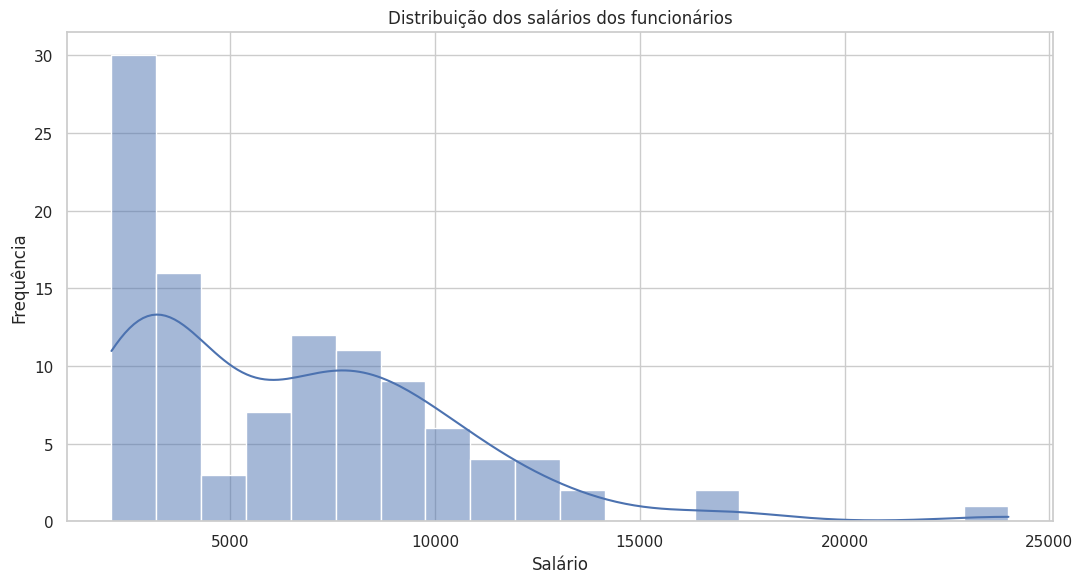

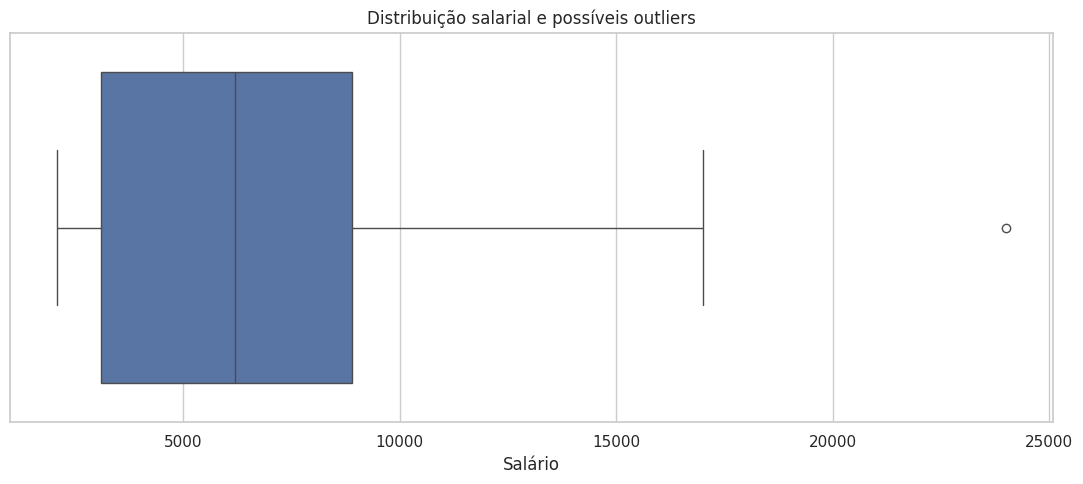

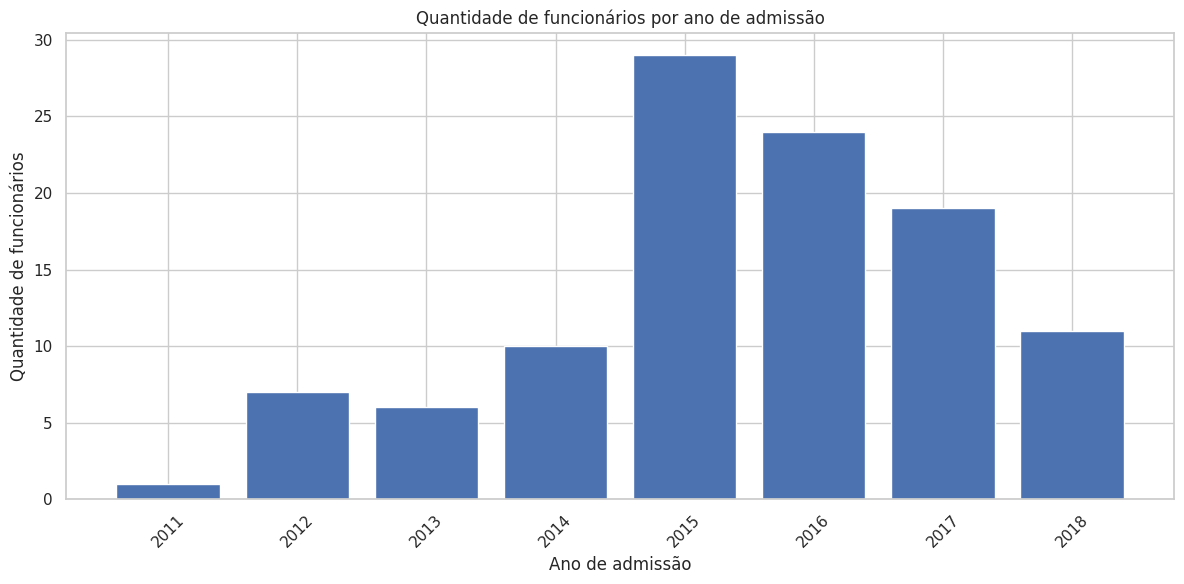

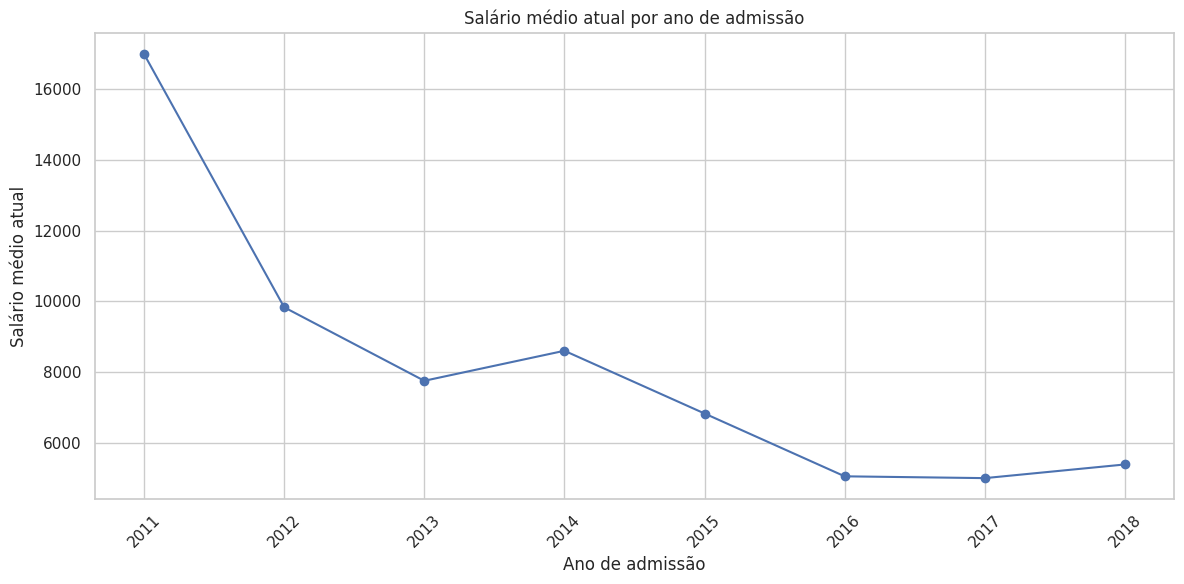


PRINCIPAIS INSIGHTS
Departamento com maior média salarial: Executive
Cargo com maior média salarial: President
País com mais funcionários: United States of America
Ano com mais admissões: 2015
Possíveis outliers salariais: 1

ANÁLISE CONCLUÍDA COM SUCESSO
Arquivo gerado: resultados_rh_bi.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# PROJETO AVALIATIVO - BUSINESS INTELLIGENCE
# ANÁLISE EXPLORATÓRIA DE RECURSOS HUMANOS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display
from pathlib import Path
import io
import zipfile
import re

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)


# ============================================================
# 1. IMPORTAÇÃO DOS ARQUIVOS - VERSÃO CORRIGIDA
# ============================================================

import pandas as pd
import io
from google.colab import files

print("Selecione os três arquivos CSV:")
uploaded = files.upload()

def localizar_arquivo(numero):
    for nome in uploaded.keys():
        nome_limpo = nome.lower().strip()

        if nome_limpo.startswith(f"query_{numero}"):
            return nome

    raise FileNotFoundError(
        f"Arquivo query_{numero} não encontrado."
    )

def ler_csv(nome):
    conteudo = uploaded[nome]

    for encoding in ["utf-8-sig", "latin-1"]:
        try:
            return pd.read_csv(
                io.BytesIO(conteudo),
                sep=None,
                engine="python",
                encoding=encoding
            )
        except UnicodeError:
            continue

    raise ValueError(f"Erro ao ler {nome}")

# Localizar automaticamente os arquivos
arquivo1 = localizar_arquivo("01")
arquivo2 = localizar_arquivo("02")
arquivo3 = localizar_arquivo("03")

# Importar os dados
df1 = ler_csv(arquivo1)
df2 = ler_csv(arquivo2)
df3 = ler_csv(arquivo3)

# Padronizar nomes das colunas
for df in [df1, df2, df3]:
    df.columns = df.columns.astype(str).str.strip().str.upper()

print("\nARQUIVOS IMPORTADOS COM SUCESSO!")

print(f"Query 1: {df1.shape}")
print(f"Query 2: {df2.shape}")
print(f"Query 3: {df3.shape}")

print("\nCOLUNAS DA QUERY 1:")
print(df1.columns.tolist())

print("\nCOLUNAS DA QUERY 2:")
print(df2.columns.tolist())

print("\nCOLUNAS DA QUERY 3:")
print(df3.columns.tolist())


# ============================================================
# 2. VALIDAÇÃO DAS COLUNAS
# ============================================================

colunas_esperadas = [
    ["EMPLOYEE_ID", "SALARY", "DEPARTMENT_NAME", "JOB_TITLE"],
    ["EMPLOYEE_ID", "CITY", "COUNTRY_NAME", "REGION_NAME"],
    ["EMPLOYEE_ID", "HIRE_DATE", "SALARY",
     "DEPARTMENT_NAME", "JOB_TITLE"]
]

for i, (df, colunas) in enumerate(
    zip([df1, df2, df3], colunas_esperadas), start=1
):
    faltando = [c for c in colunas if c not in df.columns]
    if faltando:
        raise ValueError(
            f"Query {i}: colunas ausentes: {faltando}"
        )

# ============================================================
# 3. LIMPEZA E PREPARAÇÃO
# ============================================================

def limpar_base(df):
    df = df.copy()
    df = df.dropna(how="all")
    df = df.drop_duplicates()
    for coluna in df.select_dtypes(include="object").columns:
        df[coluna] = df[coluna].str.strip()
    return df

bases_originais = [df1.copy(), df2.copy(), df3.copy()]

df1 = limpar_base(df1)
df2 = limpar_base(df2)
df3 = limpar_base(df3)

# Evitar contagem duplicada de funcionários
for df in [df1, df2, df3]:
    df.drop_duplicates(subset=["EMPLOYEE_ID"], inplace=True)

def converter_salario(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")

    texto = serie.astype("string").str.strip()
    texto = texto.str.replace(
        r"[^\d,.\-]", "", regex=True
    )

    # Aceita números com vírgula decimal e formato padrão
    com_virgula = texto.str.contains(",", na=False)
    texto.loc[com_virgula] = (
        texto.loc[com_virgula]
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(texto, errors="coerce")

df1["SALARY"] = converter_salario(df1["SALARY"])
df3["SALARY"] = converter_salario(df3["SALARY"])

df3["HIRE_DATE"] = pd.to_datetime(
    df3["HIRE_DATE"],
    errors="coerce",
    dayfirst=True
)

df3["ANO_ADMISSAO"] = df3["HIRE_DATE"].dt.year

# ============================================================
# 4. DIAGNÓSTICO DOS DADOS
# ============================================================

print("\n" + "=" * 55)
print("DIAGNÓSTICO DAS BASES")
print("=" * 55)

for i, (original, df) in enumerate(
    zip(bases_originais, [df1, df2, df3]), start=1
):
    print(f"\nQUERY {i}")
    print("Linhas originais:", len(original))
    print("Linhas após tratamento:", len(df))
    print("Duplicatas completas:",
          original.duplicated().sum())
    print("Valores ausentes:")
    print(df.isna().sum().to_string())

# ============================================================
# 5. ESTATÍSTICAS SALARIAIS
# ============================================================

salarios = df1["SALARY"].dropna()

print("\n" + "=" * 55)
print("ESTATÍSTICAS SALARIAIS")
print("=" * 55)

print(f"Quantidade: {salarios.count()}")
print(f"Média: {salarios.mean():.2f}")
print(f"Mediana: {salarios.median():.2f}")
print(f"Mínimo: {salarios.min():.2f}")
print(f"Máximo: {salarios.max():.2f}")
print(f"Desvio padrão: {salarios.std():.2f}")

# ============================================================
# 6. SALÁRIOS POR DEPARTAMENTO
# ============================================================

salarios_departamento = (
    df1.groupby("DEPARTMENT_NAME", dropna=False)
    .agg(
        FUNCIONARIOS=("EMPLOYEE_ID", "nunique"),
        MEDIA_SALARIAL=("SALARY", "mean"),
        MEDIANA_SALARIAL=("SALARY", "median"),
        SALARIO_MINIMO=("SALARY", "min"),
        SALARIO_MAXIMO=("SALARY", "max")
    )
    .sort_values("MEDIA_SALARIAL", ascending=False)
)

print("\nSALÁRIOS POR DEPARTAMENTO")
display(salarios_departamento.round(2))

# ============================================================
# 7. SALÁRIOS POR CARGO
# ============================================================

salarios_cargo = (
    df1.groupby("JOB_TITLE", dropna=False)
    .agg(
        FUNCIONARIOS=("EMPLOYEE_ID", "nunique"),
        MEDIA_SALARIAL=("SALARY", "mean"),
        MEDIANA_SALARIAL=("SALARY", "median")
    )
    .sort_values("MEDIA_SALARIAL", ascending=False)
)

print("\nSALÁRIOS POR CARGO")
display(salarios_cargo.round(2))

# ============================================================
# 8. DISTRIBUIÇÃO GEOGRÁFICA
# ============================================================

def distribuicao_geografica(coluna):
    return (
        df2.groupby(coluna, dropna=False)["EMPLOYEE_ID"]
        .nunique()
        .sort_values(ascending=False)
        .rename("FUNCIONARIOS")
    )

por_cidade = distribuicao_geografica("CITY")
por_pais = distribuicao_geografica("COUNTRY_NAME")
por_regiao = distribuicao_geografica("REGION_NAME")

print("\nFUNCIONÁRIOS POR CIDADE")
display(por_cidade.to_frame())

print("\nFUNCIONÁRIOS POR PAÍS")
display(por_pais.to_frame())

print("\nFUNCIONÁRIOS POR REGIÃO")
display(por_regiao.to_frame())

# ============================================================
# 9. ANÁLISE POR ANO DE ADMISSÃO
# ============================================================

admissoes_ano = (
    df3.dropna(subset=["ANO_ADMISSAO"])
    .groupby("ANO_ADMISSAO")
    .agg(
        FUNCIONARIOS=("EMPLOYEE_ID", "nunique"),
        MEDIA_SALARIAL=("SALARY", "mean"),
        MEDIANA_SALARIAL=("SALARY", "median"),
        SALARIO_MINIMO=("SALARY", "min"),
        SALARIO_MAXIMO=("SALARY", "max")
    )
    .sort_index()
)

print("\nANÁLISE POR ANO DE ADMISSÃO")
display(admissoes_ano.round(2))

# ============================================================
# 10. CRUZAMENTO ANO X DEPARTAMENTO
# ============================================================

pivot_admissoes = pd.pivot_table(
    df3,
    index="ANO_ADMISSAO",
    columns="DEPARTMENT_NAME",
    values="EMPLOYEE_ID",
    aggfunc="nunique",
    fill_value=0
)

print("\nADMISSÕES POR ANO E DEPARTAMENTO")
display(pivot_admissoes)

# ============================================================
# 11. IDENTIFICAÇÃO DE OUTLIERS - MÉTODO IQR
# ============================================================

q1 = salarios.quantile(0.25)
q3 = salarios.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df1[
    (df1["SALARY"] < limite_inferior) |
    (df1["SALARY"] > limite_superior)
].copy()

print("\n" + "=" * 55)
print("ANÁLISE DE OUTLIERS - IQR")
print("=" * 55)
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")
print(f"Quantidade de outliers: {len(outliers)}")

display(outliers.head(15))

# ============================================================
# 12. GRÁFICO 1 - DISTRIBUIÇÃO SALARIAL
# ============================================================

plt.figure(figsize=(11, 6))
sns.histplot(salarios, bins=20, kde=True)
plt.title("Distribuição dos salários dos funcionários")
plt.xlabel("Salário")
plt.ylabel("Frequência")
plt.tight_layout()
plt.savefig("grafico_01_salarios.png", dpi=200)
plt.show()

# ============================================================
# 13. GRÁFICO 2 - BOXPLOT SALARIAL
# ============================================================

plt.figure(figsize=(11, 5))
sns.boxplot(x=salarios)
plt.title("Distribuição salarial e possíveis outliers")
plt.xlabel("Salário")
plt.tight_layout()
plt.savefig("grafico_02_boxplot.png", dpi=200)
plt.show()

# ============================================================
# 14. GRÁFICO 3 - ADMISSÕES POR ANO
# ============================================================

plt.figure(figsize=(12, 6))
plt.bar(
    admissoes_ano.index.astype(int).astype(str),
    admissoes_ano["FUNCIONARIOS"]
)
plt.title("Quantidade de funcionários por ano de admissão")
plt.xlabel("Ano de admissão")
plt.ylabel("Quantidade de funcionários")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico_03_admissoes.png", dpi=200)
plt.show()

# ============================================================
# 15. GRÁFICO 4 - MÉDIA SALARIAL POR ANO DE ADMISSÃO
# ============================================================

plt.figure(figsize=(12, 6))
plt.plot(
    admissoes_ano.index,
    admissoes_ano["MEDIA_SALARIAL"],
    marker="o"
)
plt.title("Salário médio atual por ano de admissão")
plt.xlabel("Ano de admissão")
plt.ylabel("Salário médio atual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico_04_media_salarial.png", dpi=200)
plt.show()

# ============================================================
# 16. PRINCIPAIS INSIGHTS
# ============================================================

print("\n" + "=" * 55)
print("PRINCIPAIS INSIGHTS")
print("=" * 55)

if not salarios_departamento.empty:
    dep = salarios_departamento["MEDIA_SALARIAL"].idxmax()
    print(f"Departamento com maior média salarial: {dep}")

if not salarios_cargo.empty:
    cargo = salarios_cargo["MEDIA_SALARIAL"].idxmax()
    print(f"Cargo com maior média salarial: {cargo}")

if not por_pais.empty:
    print(f"País com mais funcionários: {por_pais.idxmax()}")

if not admissoes_ano.empty:
    print(
        "Ano com mais admissões:",
        int(admissoes_ano["FUNCIONARIOS"].idxmax())
    )

print(f"Possíveis outliers salariais: {len(outliers)}")

# ============================================================
# 17. EXPORTAÇÃO DOS RESULTADOS
# ============================================================

resultados = {
    "salarios_departamento.csv": salarios_departamento,
    "salarios_cargo.csv": salarios_cargo,
    "funcionarios_cidade.csv": por_cidade,
    "funcionarios_pais.csv": por_pais,
    "funcionarios_regiao.csv": por_regiao,
    "admissoes_ano.csv": admissoes_ano,
    "pivot_admissoes.csv": pivot_admissoes,
    "outliers_salariais.csv": outliers
}

for nome, tabela in resultados.items():
    tabela.to_csv(nome, encoding="utf-8-sig")

graficos = [
    "grafico_01_salarios.png",
    "grafico_02_boxplot.png",
    "grafico_03_admissoes.png",
    "grafico_04_media_salarial.png"
]

with zipfile.ZipFile("resultados_rh_bi.zip", "w") as zipf:
    for nome in resultados:
        zipf.write(nome)
    for nome in graficos:
        zipf.write(nome)

print("\n" + "=" * 55)
print("ANÁLISE CONCLUÍDA COM SUCESSO")
print("=" * 55)
print("Arquivo gerado: resultados_rh_bi.zip")

files.download("resultados_rh_bi.zip")
